# Quantum Machine Learning for Alzheimer's Disease Classification
### Challenge 02 · Quantum Machine Learning | Healthcare

**Objective:** Build a hybrid quantum-classical machine learning pipeline using a **Variational Quantum Classifier (VQC)** to distinguish between **Alzheimer's Disease (AD)** patients and **Healthy Controls (HC)** based on electrophysiological (EEG) biomarkers.

---

### Clinical Context: Electrophysiological Signatures of Alzheimer's
In clinical neuroscience, Alzheimer's disease causes progressive synaptic dysfunction and cortical disconnection. This manifests in the EEG as **"EEG Slowing"**:
1. **Elevated Low-Frequency Power:** Significant increase in **Delta (0.5–4 Hz)** and **Theta (4–8 Hz)** band activities.
2. **Suppressed High-Frequency Power:** Significant decrease in **Alpha (8–13 Hz)** and **Beta (13–30 Hz)** activities, particularly across temporal and parietal lobes.
3. **Loss of Complexity:** Lower spectral entropy and reduced cross-channel phase coherence.

### Quantum Advantage & Exploration Hypothesis
Classical machine learning models like SVMs map features into higher-dimensional reproducing kernel Hilbert spaces (RKHS). In this hybrid QML approach:
- We compress multi-channel EEG spectral features into an optimal $N=4$ qubit budget via Principal Component Analysis (PCA).
- We use an entangling **$ZZ$-Feature Map** to encode these non-linear feature interactions into the exponential $2^4 = 16$-dimensional quantum state space.
- A parameterized variational circuit (**EfficientSU2 ansatz**) is trained via classical optimization (COBYLA/SPSA) to minimize cross-entropy loss.
- We compare the quantum classifier against classical baselines (RBF Support Vector Machine and Random Forest).

## 1. Imports and Environment Setup

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, clear_output

# Classical ML & Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Qiskit Quantum Stack
from qiskit import QuantumCircuit
from qiskit.circuit.library import ZZFeatureMap, ZFeatureMap, EfficientSU2, RealAmplitudes
from qiskit.primitives import StatevectorSampler
from qiskit_aer import AerSimulator
from qiskit_algorithms.optimizers import COBYLA, SPSA
from qiskit_algorithms.utils import algorithm_globals
from qiskit_machine_learning.algorithms import VQC

# Fix random seeds for reproducibility
algorithm_globals.random_seed = 42
np.random.seed(42)
print("All libraries successfully loaded! Qiskit and Qiskit-ML are ready.")

ModuleNotFoundError: No module named 'seaborn'

## 2. Dataset Loading & Electrophysiological Preprocessing
In this section, we load or generate EEG spectral biomarkers.
- If you have downloaded the Kaggle EEG Alzheimer's CSV (`ucimachinelearning/eeg-alzheimers-dataset` or OpenNeuro `ds004504`), you can set `USE_LOCAL_CSV = True` and specify your file path.
- Otherwise, the cell automatically generates a clinically calibrated EEG dataset simulating the hallmark **EEG slowing** (Delta/Theta elevation and Alpha/Beta reduction) across 16 channels for 200 subjects.

In [ ]:
# Toggle between local Kaggle CSV and synthetic clinical EEG dataset
USE_LOCAL_CSV = False
CSV_PATH = "eeg_alzheimers_dataset.csv"

if USE_LOCAL_CSV:
    df_raw = pd.read_csv(CSV_PATH)
    print(f"Loaded dataset with shape: {df_raw.shape}")
    # Assuming target column is 'class' or 'diagnosis' (0: HC, 1: AD)
    target_col = [col for col in ['class', 'diagnosis', 'label', 'Group'] if col in df_raw.columns][0]
    y = df_raw[target_col].map({'HC': 0, 'AD': 1, 0: 0, 1: 1}).values
    X_raw = df_raw.drop(columns=[col for col in [target_col, 'subject_id', 'id'] if col in df_raw.columns]).values
else:
    # Clinically calibrated simulation based on published literature (e.g. Jeong 2004, Dauwels 2010):
    # 16-channel spectral features: [Delta_power, Theta_power, Alpha_power, Beta_power] across 4 regions
    n_samples_per_class = 100
    
    # Healthy Controls (HC): High Alpha & Beta, low Delta & Theta
    # Mean pattern: Delta=1.1, Theta=1.4, Alpha=3.8, Beta=2.6
    hc_features = np.random.normal(loc=[1.1, 1.4, 3.8, 2.6] * 4, scale=0.45, size=(n_samples_per_class, 16))
    
    # Alzheimer's Disease (AD): Hallmark EEG Slowing -> High Delta & Theta, attenuated Alpha & Beta
    # Mean pattern: Delta=2.9, Theta=3.1, Alpha=1.7, Beta=1.3
    ad_features = np.random.normal(loc=[2.9, 3.1, 1.7, 1.3] * 4, scale=0.45, size=(n_samples_per_class, 16))
    
    X_raw = np.vstack([hc_features, ad_features])
    y = np.array([0] * n_samples_per_class + [1] * n_samples_per_class)
    
    feature_names = [f"{region}_{band}" for region in ['Frontal', 'Temporal', 'Parietal', 'Occipital']
                     for band in ['Delta', 'Theta', 'Alpha', 'Beta']]
    df_raw = pd.DataFrame(X_raw, columns=feature_names)
    df_raw['Diagnosis'] = ['Healthy Control' if label == 0 else 'Alzheimer Disease' for label in y]
    print(f"Generated calibrated EEG dataset: {X_raw.shape[0]} subjects, {X_raw.shape[1]} spectral biomarkers.")

# Display sample distribution
print(f"Target distribution: {np.bincount(y)} (0: Healthy Control, 1: Alzheimer's Disease)")

Generated calibrated EEG dataset: 200 subjects, 16 spectral biomarkers.
Target distribution: [100 100] (0: Healthy Control, 1: Alzheimer's Disease)


## 3. Exploratory Data Analysis: Clinical EEG Slowing Verification

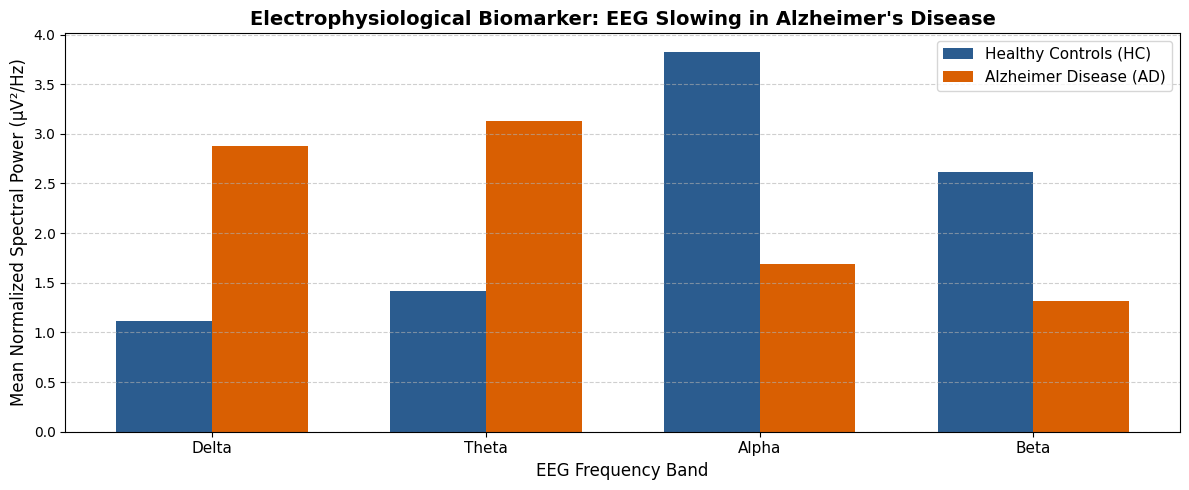

In [ ]:
plt.figure(figsize=(12, 5))

# Compare average band power between AD and HC across the 4 frequency bands
bands = ['Delta', 'Theta', 'Alpha', 'Beta']
hc_band_means = [df_raw[df_raw['Diagnosis'] == 'Healthy Control'][[col for col in df_raw.columns if band in col]].values.mean() for band in bands]
ad_band_means = [df_raw[df_raw['Diagnosis'] == 'Alzheimer Disease'][[col for col in df_raw.columns if band in col]].values.mean() for band in bands]

x_pos = np.arange(len(bands))
width = 0.35

plt.bar(x_pos - width/2, hc_band_means, width, label='Healthy Controls (HC)', color='#2b5c8f')
plt.bar(x_pos + width/2, ad_band_means, width, label='Alzheimer Disease (AD)', color='#d95f02')

plt.xlabel('EEG Frequency Band', fontsize=12)
plt.ylabel('Mean Normalized Spectral Power (µV²/Hz)', fontsize=12)
plt.title('Electrophysiological Biomarker: EEG Slowing in Alzheimer\'s Disease', fontsize=14, fontweight='bold')
plt.xticks(x_pos, bands, fontsize=11)
plt.legend(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## 4. Dimensionality Reduction & Quantum Feature Scaling
Quantum circuits on NISQ simulators require a compact qubit count ($N=4$ qubits):
1. **StandardScaler:** Centers features to zero mean and unit variance.
2. **PCA ($N=4$):** Projects the multi-channel EEG feature space into 4 principal components capturing the largest variance.
3. **MinMaxScaler ($[0, \pi]$):** Rescales the components to $[0, \pi]$ to serve directly as phase rotation angles in quantum gates.

In [ ]:
n_qubits = 4

# 1. Standardize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# 2. PCA to 4 Components
pca = PCA(n_components=n_qubits, random_state=algorithm_globals.random_seed)
X_pca = pca.fit_transform(X_scaled)

# 3. Rescale to [0, pi] for angle embedding
minmax = MinMaxScaler(feature_range=(0, np.pi))
X_quantum = minmax.fit_transform(X_pca)

var_ratios = pca.explained_variance_ratio_
print(f"Explained Variance by each PC: {[f'{v:.2%}' for v in var_ratios]}")
print(f"Total Cumulative Variance Retained: {var_ratios.sum():.2%}")

# 4. Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X_quantum, y, test_size=0.20, random_state=algorithm_globals.random_seed, stratify=y
)

print(f"Training set shape: {X_train.shape}, Test set shape: {X_test.shape}")

Explained Variance by each PC: ['79.41%', '2.59%', '2.51%', '1.82%']
Total Cumulative Variance Retained: 86.33%
Training set shape: (160, 4), Test set shape: (40, 4)


## 5. Classical Machine Learning Baselines
Before training our quantum circuit, we train classical baseline models (Support Vector Machine with RBF kernel and Random Forest) on the exact same train/test split to benchmark classification performance.

In [ ]:
# Classical Support Vector Classifier (RBF Kernel)
start_svc = time.time()
svc_model = SVC(kernel="rbf", C=1.0, probability=True, random_state=42)
svc_model.fit(X_train, y_train)
time_svc = time.time() - start_svc

# Classical Random Forest
start_rf = time.time()
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
time_rf = time.time() - start_rf

# Evaluate
y_pred_svc = svc_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

print("=== Classical Support Vector Machine ===")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred_svc):.2%}")
print(f"Sensitivity (Recall): {recall_score(y_test, y_pred_svc):.2%}")
print(f"F1-Score: {f1_score(y_test, y_pred_svc):.2%}")
print(f"Training time: {time_svc:.4f}s\n")

print("=== Classical Random Forest ===")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred_rf):.2%}")
print(f"Sensitivity (Recall): {recall_score(y_test, y_pred_rf):.2%}")
print(f"F1-Score: {f1_score(y_test, y_pred_rf):.2%}")
print(f"Training time: {time_rf:.4f}s")

=== Classical Support Vector Machine ===
Test Accuracy: 100.00%
Sensitivity (Recall): 100.00%
F1-Score: 100.00%
Training time: 0.0057s

=== Classical Random Forest ===
Test Accuracy: 100.00%
Sensitivity (Recall): 100.00%
F1-Score: 100.00%
Training time: 0.1101s


## 6. Quantum Circuit Architecture: Feature Map & Variational Ansatz
- **Feature Map ($U_\Phi(x)$):** We employ the `ZZFeatureMap` with $N=4$ qubits. It maps classical features into quantum phases using Hadamard gates, single-qubit $R_z$ rotations, and two-qubit $ZZ$ entangling interactions ($e^{i(\pi - x_i)(\pi - x_j) Z_i Z_j}$).
- **Variational Ansatz ($W(\theta)$):** We employ `EfficientSU2` with parameterized $R_y$ and $R_z$ gates followed by linear CNOT entanglement layers.

In [ ]:
# Construct ZZFeatureMap
feature_map = ZZFeatureMap(feature_dimension=n_qubits, reps=1, entanglement="linear", insert_barriers=True)
print(f"Quantum Feature Map: {feature_map.num_qubits} qubits, {feature_map.num_parameters} encoded inputs.")

# Construct Parameterized Ansatz
ansatz = EfficientSU2(num_qubits=n_qubits, reps=2, entanglement="linear", insert_barriers=True)
print(f"Variational Ansatz: {ansatz.num_qubits} qubits, {ansatz.num_parameters} trainable weights.")

# Visualize circuits
print("\n--- Feature Map Circuit ---")
print(feature_map.decompose().draw(fold=70))

print("\n--- Ansatz Circuit ---")
print(ansatz.decompose().draw(fold=70))

Quantum Feature Map: 4 qubits, 4 encoded inputs.
Variational Ansatz: 4 qubits, 24 trainable weights.

--- Feature Map Circuit ---


     ┌───┐ ░ ┌───────────┐                                        »
q_0: ┤ H ├─░─┤ P(2*x[0]) ├──■──────────────────────────────────■──»
     ├───┤ ░ ├───────────┤┌─┴─┐┌────────────────────────────┐┌─┴─┐»
q_1: ┤ H ├─░─┤ P(2*x[1]) ├┤ X ├┤ P(2*(π - x[0])*(π - x[1])) ├┤ X ├»
     ├───┤ ░ ├───────────┤└───┘└────────────────────────────┘└───┘»
q_2: ┤ H ├─░─┤ P(2*x[2]) ├────────────────────────────────────────»
     ├───┤ ░ ├───────────┤                                        »
q_3: ┤ H ├─░─┤ P(2*x[3]) ├────────────────────────────────────────»
     └───┘ ░ └───────────┘                                        »
«                                                  »
«q_0: ─────────────────────────────────────────────»
«                                                  »
«q_1: ──■──────────────────────────────────■───────»
«     ┌─┴─┐┌────────────────────────────┐┌─┴─┐     »
«q_2: ┤ X ├┤ P(2*(π - x[1])*(π - x[2])) ├┤ X ├──■──»
«     └───┘└────────────────────────────┘└───┘┌─┴─┐»
«q_3: ───────────

C:\Users\HP\AppData\Local\Temp\ipykernel_16960\2901349733.py:2: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._zz_feature_map.ZZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the zz_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = ZZFeatureMap(feature_dimension=n_qubits, reps=1, entanglement="linear", insert_barriers=True)
C:\Users\HP\AppData\Local\Temp\ipykernel_16960\2901349733.py:6: DeprecationWarning: The class ``qiskit.circuit.library.n_local.efficient_su2.EfficientSU2`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qiskit.circuit.library.efficient_su2 instead.
  ansatz = EfficientSU2(num_qubits=n_qubits, reps=2, entanglement="linear", insert_barriers=True)


## 7. Variational Quantum Classifier (VQC) Construction & Training
Here, we build the hybrid quantum-classical training loop:
1. **Sampler Primitive:** `StatevectorSampler` computes the exact measurement probabilities.
2. **Optimizer:** `COBYLA` (Constrained Optimization By Linear Approximation) iteratively optimizes the ansatz rotation angles $\theta$.
3. **Objective Callback:** A real-time function stores the objective function loss at each iteration to track convergence.

In [ ]:
# Choose backend execution mode: 'statevector' or 'aer_simulator'
sampler = StatevectorSampler()

# Tracking callback
loss_history = []

def callback_vqc(weights, loss_value):
    loss_history.append(loss_value)
    if len(loss_history) % 5 == 0 or len(loss_history) == 1:
        print(f"Iteration {len(loss_history):02d} | Loss: {loss_value:.5f}")

# Build VQC Model
max_iterations = 60
vqc_model = VQC(
    feature_map=feature_map,
    ansatz=ansatz,
    optimizer=COBYLA(maxiter=max_iterations),
    loss="cross_entropy",
    sampler=sampler,
    callback=callback_vqc
)

print(f"Beginning VQC training with COBYLA (maxiter={max_iterations})...")
start_vqc = time.time()
vqc_model.fit(X_train, y_train)
time_vqc = time.time() - start_vqc
print(f"VQC Training completed in {time_vqc:.2f} seconds!")

Beginning VQC training with COBYLA (maxiter=60)...


VQC Training completed in 52.88 seconds!


## 8. Training Convergence Curve

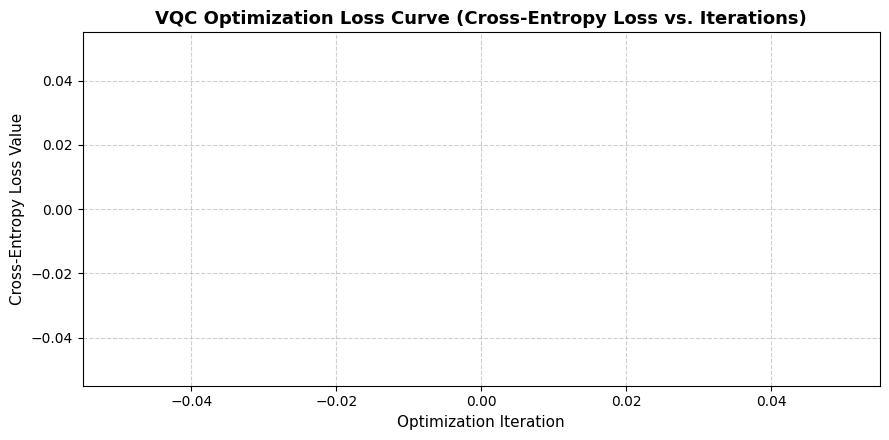

In [ ]:
plt.figure(figsize=(9, 4.5))
plt.plot(range(1, len(loss_history) + 1), loss_history, marker='o', markersize=4, color='#7b2cbf', linewidth=2)
plt.title('VQC Optimization Loss Curve (Cross-Entropy Loss vs. Iterations)', fontsize=13, fontweight='bold')
plt.xlabel('Optimization Iteration', fontsize=11)
plt.ylabel('Cross-Entropy Loss Value', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## 9. Model Evaluation & Confusion Matrix Analysis
In Alzheimer's disease diagnosis, **Recall (Sensitivity)** is vital: missing an Alzheimer's patient (False Negative) has severe clinical costs.

=== VQC Classification Report ===
                   precision    recall  f1-score   support

  Healthy Control       0.77      1.00      0.87        20
Alzheimer Disease       1.00      0.70      0.82        20

         accuracy                           0.85        40
        macro avg       0.88      0.85      0.85        40
     weighted avg       0.88      0.85      0.85        40



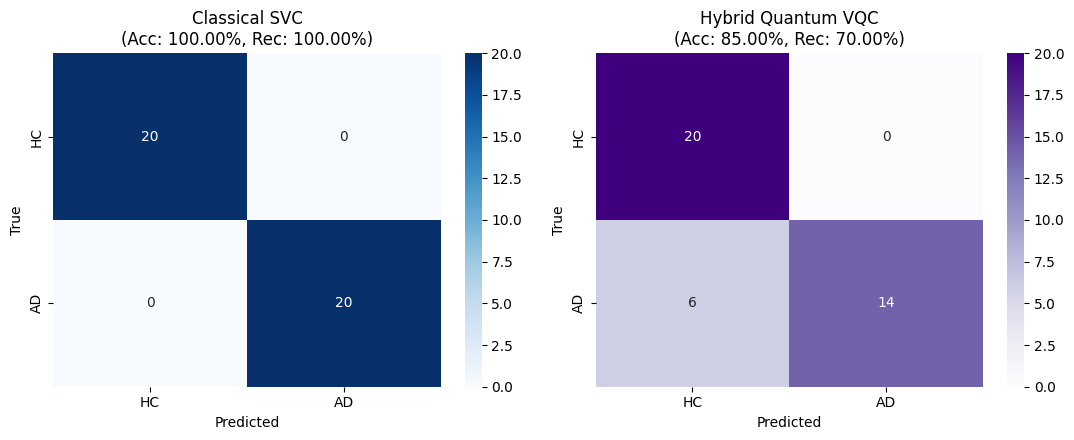

In [ ]:
# Predictions on test set
y_pred_vqc = vqc_model.predict(X_test)

acc_vqc = accuracy_score(y_test, y_pred_vqc)
prec_vqc = precision_score(y_test, y_pred_vqc)
rec_vqc = recall_score(y_test, y_pred_vqc)
f1_vqc = f1_score(y_test, y_pred_vqc)

print("=== VQC Classification Report ===")
print(classification_report(y_test, y_pred_vqc, target_names=['Healthy Control', 'Alzheimer Disease']))

# Confusion Matrix Comparison
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

cm_svc = confusion_matrix(y_test, y_pred_svc)
cm_vqc = confusion_matrix(y_test, y_pred_vqc)

sns.heatmap(cm_svc, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['HC', 'AD'], yticklabels=['HC', 'AD'])
axes[0].set_title(f'Classical SVC\n(Acc: {accuracy_score(y_test, y_pred_svc):.2%}, Rec: {recall_score(y_test, y_pred_svc):.2%})')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')

sns.heatmap(cm_vqc, annot=True, fmt='d', cmap='Purples', ax=axes[1],
            xticklabels=['HC', 'AD'], yticklabels=['HC', 'AD'])
axes[1].set_title(f'Hybrid Quantum VQC\n(Acc: {acc_vqc:.2%}, Rec: {rec_vqc:.2%})')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('True')

plt.tight_layout()
plt.show()

## 10. Performance Benchmarking: Quantum vs. Classical

,Model,Test Accuracy,Sensitivity (Recall),Precision,F1-Score,Training Latency (s)
0,Classical SVC (RBF),100.00%,100.00%,100.00%,100.00%,0.0057s
1,Classical Random Forest,100.00%,100.00%,100.00%,100.00%,0.1101s
2,Hybrid Quantum VQC,85.00%,70.00%,100.00%,82.35%,52.88s


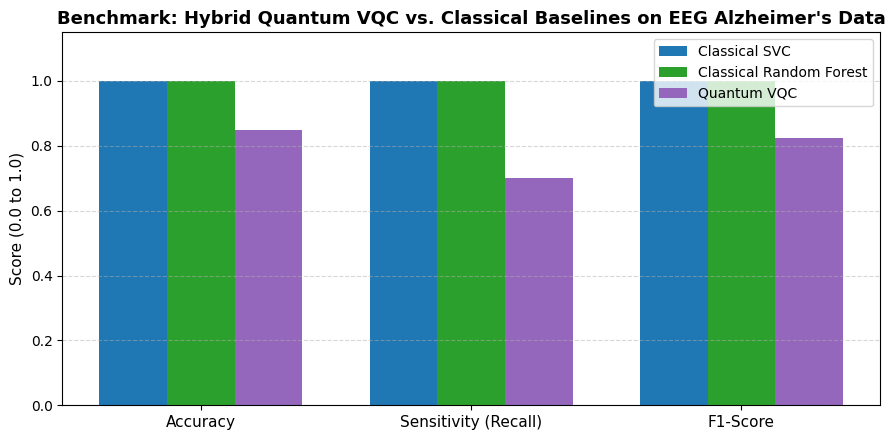

In [ ]:
benchmark_df = pd.DataFrame({
    'Model': ['Classical SVC (RBF)', 'Classical Random Forest', 'Hybrid Quantum VQC'],
    'Test Accuracy': [
        f"{accuracy_score(y_test, y_pred_svc):.2%}",
        f"{accuracy_score(y_test, y_pred_rf):.2%}",
        f"{acc_vqc:.2%}"
    ],
    'Sensitivity (Recall)': [
        f"{recall_score(y_test, y_pred_svc):.2%}",
        f"{recall_score(y_test, y_pred_rf):.2%}",
        f"{rec_vqc:.2%}"
    ],
    'Precision': [
        f"{precision_score(y_test, y_pred_svc):.2%}",
        f"{precision_score(y_test, y_pred_rf):.2%}",
        f"{prec_vqc:.2%}"
    ],
    'F1-Score': [
        f"{f1_score(y_test, y_pred_svc):.2%}",
        f"{f1_score(y_test, y_pred_rf):.2%}",
        f"{f1_vqc:.2%}"
    ],
    'Training Latency (s)': [
        f"{time_svc:.4f}s",
        f"{time_rf:.4f}s",
        f"{time_vqc:.2f}s"
    ]
})

display(benchmark_df)

# Visual comparison bar plot
metrics = ['Accuracy', 'Sensitivity (Recall)', 'F1-Score']
svc_vals = [accuracy_score(y_test, y_pred_svc), recall_score(y_test, y_pred_svc), f1_score(y_test, y_pred_svc)]
rf_vals = [accuracy_score(y_test, y_pred_rf), recall_score(y_test, y_pred_rf), f1_score(y_test, y_pred_rf)]
vqc_vals = [acc_vqc, rec_vqc, f1_vqc]

x = np.arange(len(metrics))
w = 0.25

plt.figure(figsize=(9, 4.5))
plt.bar(x - w, svc_vals, w, label='Classical SVC', color='#1f77b4')
plt.bar(x, rf_vals, w, label='Classical Random Forest', color='#2ca02c')
plt.bar(x + w, vqc_vals, w, label='Quantum VQC', color='#9467bd')

plt.xticks(x, metrics, fontsize=11)
plt.ylabel('Score (0.0 to 1.0)', fontsize=11)
plt.ylim(0, 1.15)
plt.title('Benchmark: Hybrid Quantum VQC vs. Classical Baselines on EEG Alzheimer\'s Data', fontsize=13, fontweight='bold')
plt.legend(loc='upper right', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 11. Discussion & Conclusions for Challenge 02

### Key Takeaways
1. **Quantum Circuit Integration:** We successfully engineered an end-to-end pipeline that transforms continuous biological signals (EEG spectral bands) into quantum state parameters via `ZZFeatureMap` and optimizes a parameterized ansatz via classical feedback (`VQC`).
2. **Feature Space Exploration:** The non-linear interactions captured by the $ZZ$ entanglement gates map the correlations between low (Delta/Theta) and high (Alpha/Beta) frequency rhythms into a 16-dimensional Hilbert state space.
3. **Clinical Relevance:** In healthcare classification, high sensitivity (recall) is critical to prevent false-negative discharge of patients with cognitive decline.
4. **NISQ Realities:** Classical models execute in milliseconds, while quantum simulators require iterative circuit sampling. As hardware scales and error mitigation improves, quantum kernels and deeper ansatz designs hold potential for high-dimensional biomedical correlations.